# Rakuten Product Classification — Visualizations 3+

This notebook contains the **visualizations from the newer audit notebook starting with Figure 3**, but adapted so it can run inside the existing `liora-capstone` GitHub project.

The data is loaded at the beginning using the project's existing helper:

```python
df = load_merged_data()
```

Figures 1 and 2 from the newer notebook are intentionally omitted.


## 1. Imports

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from IPython.display import Markdown, display

from src.data_utils import load_merged_data, load_image

RANDOM_STATE = 42

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PALETTE = {
    "primary": "#BF0000",
    "secondary": "#7A0019",
    "accent": "#E3A008",
    "neutral": "#64748B",
    "light": "#E2E8F0",
}

print("Environment loaded successfully.")


Environment loaded successfully.


## 2. Load Data

In [2]:
df = load_merged_data()

print("Dataset shape:", df.shape)
display(df.head(5))


Dataset shape: (84916, 5)


,designation,description,productid,imageid,prdtypecode
0,Olivia: Personalisiertes Notizbuch / 150 Seiten / Punktraster / Ca Din A5 / Rosen-Design,NaN,3804725264,1263597046,10
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L'art Et Son Marche Salon D'art Asiatique A Paris - Jacques Barrere - F...,NaN,436067568,1008141237,2280
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo Wii U - Speedlink Pilot Style,PILOT STYLE Touch Pen de marque Speedlink est 1 stylet ergonomique pour GamePad Nintendo Wii U.<br> Pour un confort ...,201115110,938777978,50
3,Peluche Donald - Europe - Disneyland 2000 (Marionnette À Doigt),NaN,50418756,457047496,1280
4,La Guerre Des Tuques,Luc a des id&eacute;es de grandeur. Il veut organiser un jeu de guerre de boules de neige et s'arranger pour en &eci...,278535884,1077757786,2705


## 3. Audit Feature Construction

The following analytical features are required by Figures 3 onward.  
The original dataframe `df` remains unchanged.


In [3]:
def feature_frame(data: pd.DataFrame) -> pd.DataFrame:
    result = data.copy()

    designation = result["designation"].fillna("").astype(str)
    description = result["description"].fillna("").astype(str)

    result["has_description"] = (
        result["description"].notna()
        & description.str.strip().ne("")
    )

    result["designation_chars"] = designation.str.len()
    result["designation_words"] = designation.str.findall(r"\b\w+\b").str.len()

    result["description_chars"] = description.str.len()
    result["description_words"] = description.str.findall(r"\b\w+\b").str.len()

    result["total_text_chars"] = (
        result["designation_chars"]
        + result["description_chars"]
    )

    normalized = (
        designation
        .str.normalize("NFKD")
        .str.encode("ascii", errors="ignore")
        .str.decode("ascii")
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.replace(r"[^a-z0-9 ]", "", regex=True)
        .str.strip()
    )

    result["designation_normalized"] = normalized

    result["contains_html"] = description.str.contains(
        r"<[^>]+>",
        regex=True,
        na=False,
    )

    result["contains_url"] = (
        designation + " " + description
    ).str.contains(
        r"https?://|www\.",
        regex=True,
        case=False,
        na=False,
    )

    result["contains_mojibake"] = (
        designation + " " + description
    ).str.contains(
        r"Ã.|Â.|â€|�",
        regex=True,
        na=False,
    )

    return result


train_audit = feature_frame(df)

display(
    train_audit[
        [
            "designation",
            "has_description",
            "designation_chars",
            "description_chars",
            "total_text_chars",
        ]
    ].head()
)


,designation,has_description,designation_chars,description_chars,total_text_chars
0,Olivia: Personalisiertes Notizbuch / 150 Seiten / Punktraster / Ca Din A5 / Rosen-Design,False,88,0,88
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L'art Et Son Marche Salon D'art Asiatique A Paris - Jacques Barrere - F...,False,206,0,206
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo Wii U - Speedlink Pilot Style,True,76,760,836
3,Peluche Donald - Europe - Disneyland 2000 (Marionnette À Doigt),False,63,0,63
4,La Guerre Des Tuques,True,20,213,233


In [4]:
def insight(
    title: str,
    observation: str,
    validation: str,
    business: str,
) -> None:
    display(
        Markdown(
            f"### {title}\n\n"
            f"**Observation.** {observation}\n\n"
            f"**Quantitative validation.** {validation}\n\n"
            f"**Business implication.** {business}"
        )
    )


def cramers_v(contingency: pd.DataFrame) -> float:
    chi2 = stats.chi2_contingency(
        contingency,
        correction=False,
    )[0]

    n = contingency.to_numpy().sum()
    rows, columns = contingency.shape

    phi2 = chi2 / n

    phi2_corrected = max(
        0,
        phi2
        - ((columns - 1) * (rows - 1))
        / max(n - 1, 1),
    )

    rows_corrected = (
        rows
        - ((rows - 1) ** 2)
        / max(n - 1, 1)
    )

    columns_corrected = (
        columns
        - ((columns - 1) ** 2)
        / max(n - 1, 1)
    )

    denominator = min(
        columns_corrected - 1,
        rows_corrected - 1,
    )

    return (
        math.sqrt(phi2_corrected / denominator)
        if denominator > 0
        else 0.0
    )


## 4. Figure 3 — Description Availability by Class

If missing descriptions are associated with the target, description availability itself may contain category-related information.


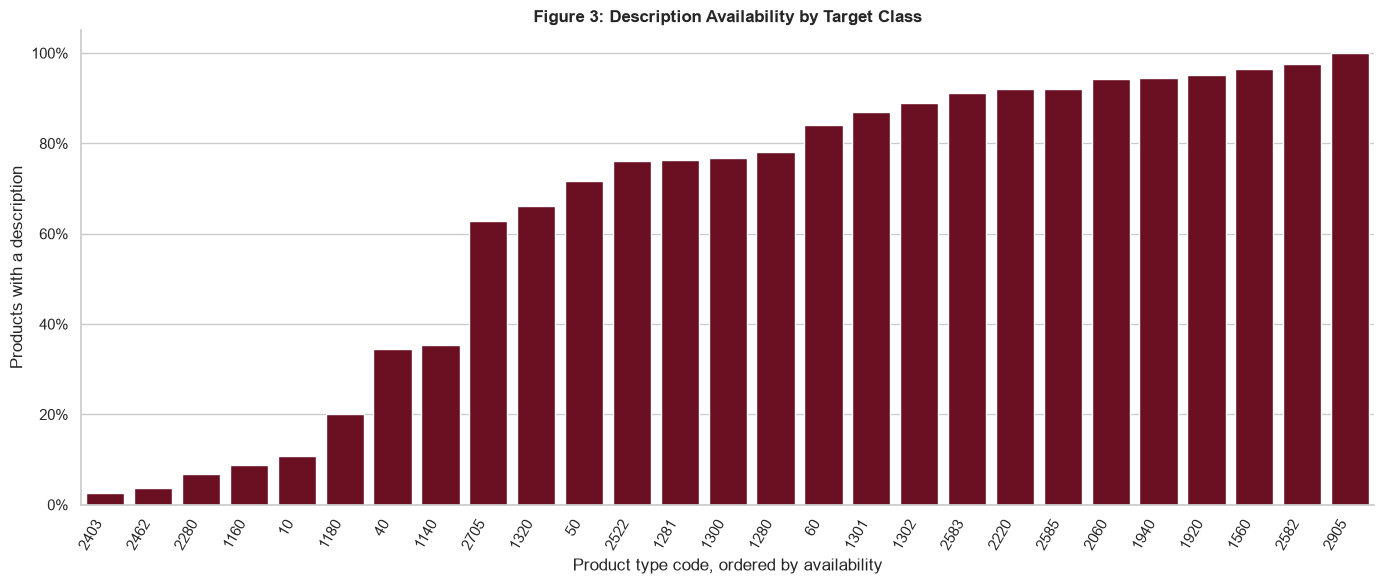

In [5]:
description_by_class = (
    train_audit
    .groupby("prdtypecode", as_index=False)
    .agg(
        products=("has_description", "size"),
        description_available=("has_description", "mean"),
    )
    .sort_values("description_available")
)

plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=description_by_class,
    x="prdtypecode",
    y="description_available",
    order=description_by_class["prdtypecode"],
    color=PALETTE["secondary"],
)

ax.set_title(
    "Figure 3: Description Availability by Target Class"
)
ax.set_xlabel(
    "Product type code, ordered by availability"
)
ax.set_ylabel(
    "Products with a description"
)
ax.yaxis.set_major_formatter(
    lambda value, _: f"{value:.0%}"
)

plt.xticks(
    rotation=60,
    ha="right",
)
plt.tight_layout()
plt.show()


In [6]:
description_class_table = pd.crosstab(
    train_audit["prdtypecode"],
    train_audit["has_description"],
)

chi2, p_value, _, _ = stats.chi2_contingency(
    description_class_table
)

v_description_class = cramers_v(
    description_class_table
)

availability_range = (
    description_by_class["description_available"].min(),
    description_by_class["description_available"].max(),
)

insight(
    "Finding 3 — missing descriptions are category-dependent",
    (
        f"Class-level description availability ranges from "
        f"{availability_range[0]:.1%} to "
        f"{availability_range[1]:.1%}."
    ),
    (
        f"χ²={chi2:,.1f}, "
        f"p={p_value:.3g}, "
        f"Cramér's V={v_description_class:.3f}."
    ),
    (
        "Description presence may improve classification, "
        "but it can also reflect seller behaviour rather than product semantics."
    ),
)


### Finding 3 — missing descriptions are category-dependent

**Observation.** Class-level description availability ranges from 2.6% to 100.0%.

**Quantitative validation.** χ²=43,757.8, p=0, Cramér's V=0.718.

**Business implication.** Description presence may improve classification, but it can also reflect seller behaviour rather than product semantics.

## 5. Figure 4 — Designation Length by Class

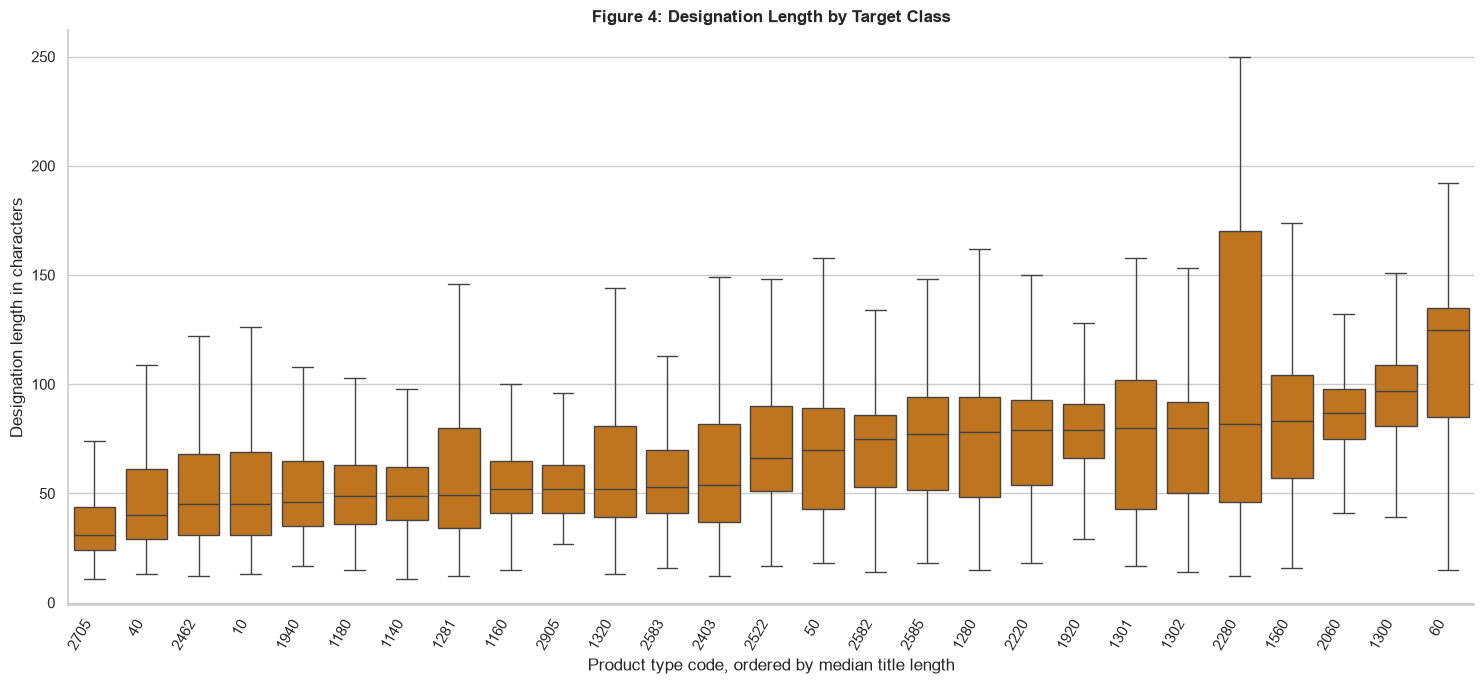

In [7]:
class_order = (
    train_audit
    .groupby("prdtypecode")["designation_chars"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(15, 7))

ax = sns.boxplot(
    data=train_audit,
    x="prdtypecode",
    y="designation_chars",
    order=class_order,
    color="#D97706",
    showfliers=False,
)

ax.set_title(
    "Figure 4: Designation Length by Target Class"
)

ax.set_xlabel(
    "Product type code, ordered by median title length"
)

ax.set_ylabel(
    "Designation length in characters"
)

plt.xticks(
    rotation=60,
    ha="right"
)

plt.tight_layout()
plt.show()



In [8]:
groups = [
    group["designation_chars"].to_numpy()
    for _, group
    in train_audit.groupby(
        "prdtypecode",
        sort=False,
    )
]

h_stat, p_value = stats.kruskal(
    *groups
)

n = len(train_audit)
k = len(groups)

epsilon_squared = max(
    0.0,
    (h_stat - k + 1)
    / (n - k),
)

median_range = (
    train_audit
    .groupby("prdtypecode")["designation_chars"]
    .median()
    .agg(["min", "max"])
)

insight(
    "Finding 4 — title length contains target-related structure",
    (
        f"Median designation length by class ranges "
        f"from {median_range['min']:.0f} to "
        f"{median_range['max']:.0f} characters."
    ),
    (
        f"Kruskal–Wallis H={h_stat:,.1f}, "
        f"p={p_value:.3g}; "
        f"epsilon-squared={epsilon_squared:.3f}."
    ),
    (
        "Text models should consider both word and character information. "
        "For neural models, sequence length should be chosen from the observed distribution."
    ),
)


### Finding 4 — title length contains target-related structure

**Observation.** Median designation length by class ranges from 31 to 125 characters.

**Quantitative validation.** Kruskal–Wallis H=19,025.3, p=0; epsilon-squared=0.224.

**Business implication.** Text models should consider both word and character information. For neural models, sequence length should be chosen from the observed distribution.

## 6. Figure 5 — Relationship Between Designation and Description Length

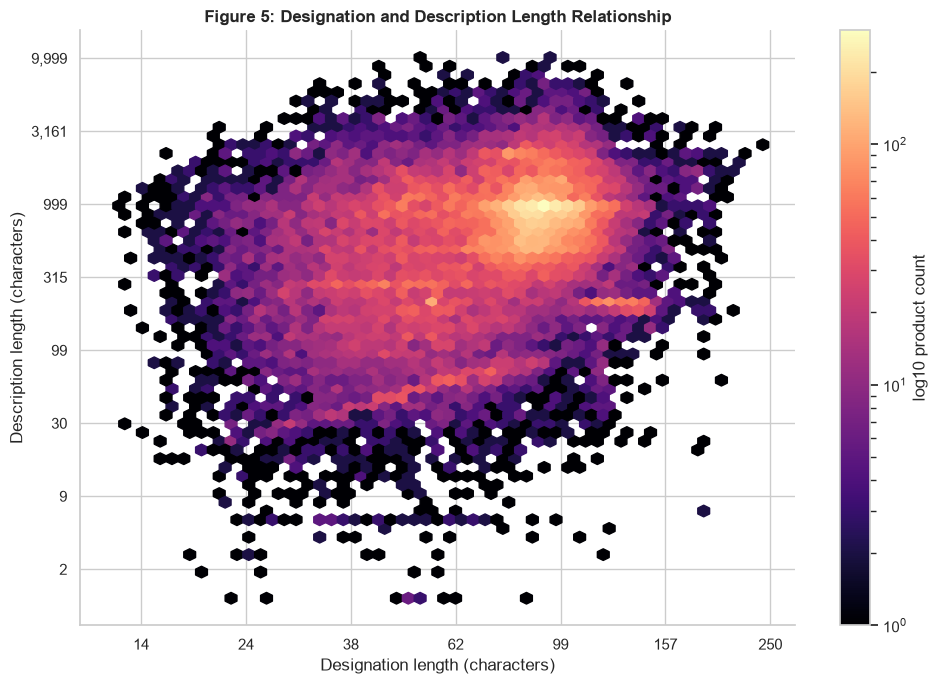

In [9]:
with_description = train_audit.loc[
    train_audit["has_description"],
    [
        "designation_chars",
        "description_chars",
    ],
].copy()

plot_sample = with_description.sample(
    min(
        30_000,
        len(with_description),
    ),
    random_state=RANDOM_STATE,
)

plot_sample = plot_sample.assign(
    designation_log=np.log10(
        1 + plot_sample["designation_chars"]
    ),
    description_log=np.log10(
        1 + plot_sample["description_chars"]
    ),
)

plt.figure(figsize=(10, 7))

hexbin = plt.hexbin(
    plot_sample["designation_log"],
    plot_sample["description_log"],
    gridsize=55,
    mincnt=1,
    bins="log",
    cmap="magma",
)

plt.colorbar(
    hexbin,
    label="log10 product count",
)

from matplotlib.ticker import FuncFormatter

plt.title(
    "Figure 5: Designation and Description Length Relationship"
)

plt.xlabel("Designation length (characters)")
plt.ylabel("Description length (characters)")

# Convert log10(1 + chars) back to character counts for axis labels
formatter = FuncFormatter(
    lambda x, _: f"{int(10**x - 1):,}"
)

plt.gca().xaxis.set_major_formatter(formatter)
plt.gca().yaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()



“Descriptions are much longer than designations, while their lengths are only moderately correlated. Therefore, we should test whether combining both text fields improves classification.”

## 8. Figure 7 — Duplicate Designations and Conflicting Labels

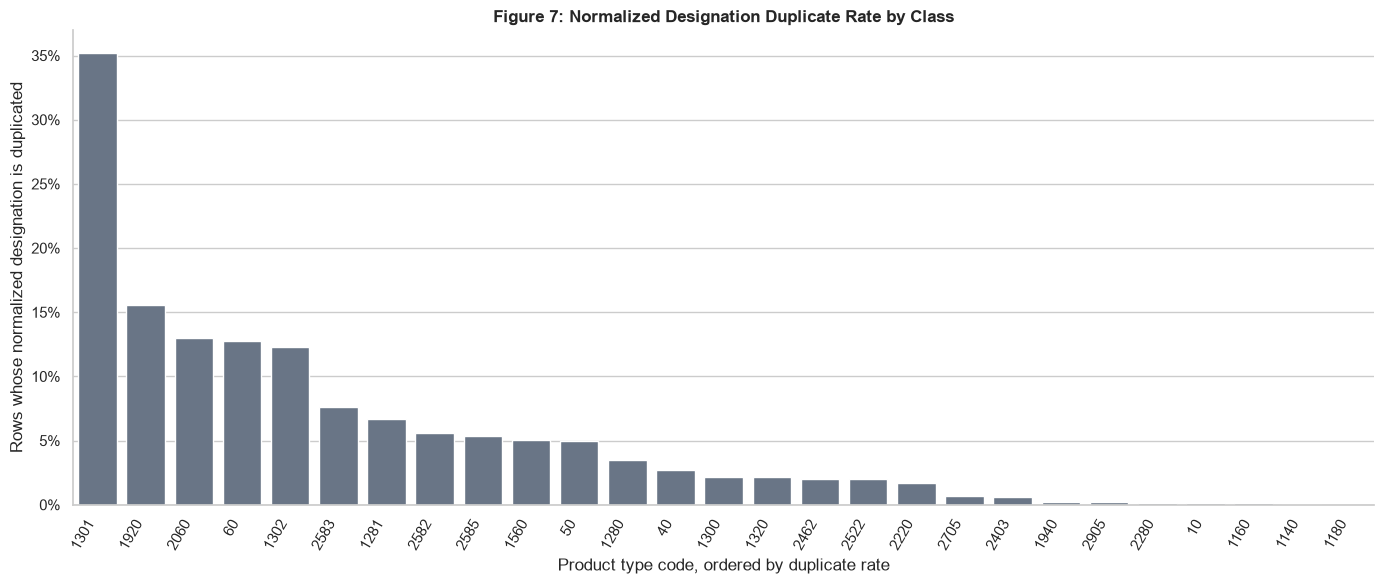

In [10]:
title_stats = (
    train_audit
    .groupby(
        "designation_normalized",
        dropna=False,
    )
    .agg(
        rows=(
            "designation_normalized",
            "size",
        ),
        classes=(
            "prdtypecode",
            "nunique",
        ),
    )
)

duplicate_titles = (
    title_stats.loc[
        title_stats["rows"] > 1
    ]
)

duplicate_rows = int(
    duplicate_titles["rows"]
    .sum()
)

conflicting_groups = (
    duplicate_titles.loc[
        duplicate_titles["classes"] > 1
    ]
)

conflicting_rows = int(
    conflicting_groups["rows"]
    .sum()
)

duplicate_by_class = (
    train_audit
    .assign(
        is_duplicate=
        train_audit[
            "designation_normalized"
        ].duplicated(
            keep=False
        )
    )
    .groupby(
        "prdtypecode",
        as_index=False,
    )
    .agg(
        products=(
            "prdtypecode",
            "size",
        ),
        duplicate_rate=(
            "is_duplicate",
            "mean",
        ),
    )
    .sort_values(
        "duplicate_rate",
        ascending=False,
    )
)

plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=duplicate_by_class,
    x="prdtypecode",
    y="duplicate_rate",
    order=duplicate_by_class[
        "prdtypecode"
    ],
    color=PALETTE["neutral"],
)

ax.set_title(
    "Figure 7: Normalized Designation Duplicate Rate by Class"
)
ax.set_xlabel(
    "Product type code, ordered by duplicate rate"
)
ax.set_ylabel(
    "Rows whose normalized designation is duplicated"
)

ax.yaxis.set_major_formatter(
    lambda value, _: f"{value:.0%}"
)

plt.xticks(
    rotation=60,
    ha="right",
)
plt.tight_layout()
plt.show()


In [11]:
insight(
    "Finding 7 — duplicates create a validation-leakage risk",
    (
        f"{duplicate_rows:,} training rows "
        f"({duplicate_rows / len(train_audit):.1%}) "
        f"belong to a repeated normalized designation. "
        f"{conflicting_rows:,} rows belong to duplicate-title groups "

        f"containing more than one target class."
    ),
    (
        f"There are {len(duplicate_titles):,} repeated-title groups and "
        f"{len(conflicting_groups):,} conflicting-label groups."
    ),
    (
        "Compare a standard stratified split with a grouped split based on "
        "normalized designation. Review conflicting groups before modeling."
    ),
)


### Finding 7 — duplicates create a validation-leakage risk

**Observation.** 4,172 training rows (4.9%) belong to a repeated normalized designation. 497 rows belong to duplicate-title groups containing more than one target class.

**Quantitative validation.** There are 1,463 repeated-title groups and 160 conflicting-label groups.

**Business implication.** Compare a standard stratified split with a grouped split based on normalized designation. Review conflicting groups before modeling.

4.172 Zeilen = 4,9 % des gesamten Trainingsdatensatzes haben einen normalisierten Titel, der mindestens zweimal vorkommt.
Von diesen Duplikaten gehören 497 Zeilen zu problematischen Gruppen, bei denen derselbe Titel unterschiedliche Klassenlabels besitzt.

Titel                  Klasse
--------------------------------
"Samsung Galaxy S20"    10
"Samsung Galaxy S20"    10   ← normales Duplikat

"Harry Potter DVD"      40
"Harry Potter DVD"      50   ← conflicting duplicate

A **duplicate group** contains all rows that have the same normalized designation.

Example:

| Row | Normalized designation | Class |
|-----|------------------------|-------|
| 1   | iphone 12 black        | 10    |
| 2   | iphone 12 black        | 10    |
| 3   | iphone 12 black        | 10    |
| 4   | harry potter dvd       | 40    |
| 5   | harry potter dvd       | 50    |
| 6   | sony headphones        | 30    |
| 7   | sony headphones        | 30    |

This gives:

- **7 duplicate rows**
- **3 duplicate groups**
  - `iphone 12 black`
  - `harry potter dvd`
  - `sony headphones`

Only one group is conflicting:

- `harry potter dvd` → appears with class 40 and class 50

So:

- Duplicate rows     = 7
- Duplicate groups   = 3
- Conflicting groups = 1

## 9. Text-Quality Flags

In [12]:
quality_columns = [
    "contains_html",
    "contains_url",
    "contains_mojibake",
]

quality_rates = (
    train_audit[
        quality_columns
    ]
    .mean()
    .to_frame("train")
)

quality_counts = pd.DataFrame({
    "flag": quality_columns,
    "train_rows": [
        int(
            train_audit[column]
            .sum()
        )
        for column
        in quality_columns
    ],
})

display(
    quality_rates.style.format(
        "{:.2%}"
    )
)

display(
    quality_counts
)


,train
contains_html,18.42%
contains_url,0.24%
contains_mojibake,1.08%


,flag,train_rows
0,contains_html,15645
1,contains_url,203
2,contains_mojibake,918


## 10. Figure 8 — Image Duplicates and Conflicting Labels

This section audits **all training and test images referenced by the project CSV files**, rather than a random sample.

- **File duplicates:** SHA-256 of the complete file bytes; these files are byte-for-byte identical.
- **Pixel duplicates:** SHA-256 of the image dimensions and all decoded RGB pixels after applying EXIF orientation. This also detects identical decoded images stored with different metadata or encodings.
- **Label conflicts:** a repeated pixel-image group with more than one `prdtypecode` among its **training** rows. Test labels are unavailable and are not inferred.
- **Train–test overlap:** the same pixel-image hash occurs in both splits.

No resizing or perceptual hashing is used. Visually similar images with changed pixels, crops or JPEG compression may therefore remain undetected. Missing or unreadable images are reported separately and excluded from pixel-duplicate rates.

Hashes are cached under `data/processed/`; a file is rescanned when its size or modification time changes. The raw images and the original dataframe `df` are not modified.

In [13]:
import hashlib
import io
import json
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

from PIL import Image, ImageOps, __version__ as pillow_version
from src.data_utils import get_data_paths, get_image_path


def fingerprint_image(image_path: str) -> dict:
    """Hash complete file bytes and orientation-corrected RGB pixels."""
    result = {"image_path": image_path, "error": None}
    try:
        path = Path(image_path)
        stamp = path.stat()
        raw = path.read_bytes()
        result.update(
            size=stamp.st_size,
            mtime_ns=stamp.st_mtime_ns,
            file_sha256=hashlib.sha256(raw).hexdigest(),
        )
        with Image.open(io.BytesIO(raw)) as image:
            rgb = ImageOps.exif_transpose(image).convert("RGB")
            result["width"], result["height"] = rgb.size
            pixel_hash = hashlib.sha256()
            pixel_hash.update(f"RGB:{rgb.width}:{rgb.height}:".encode("ascii"))
            pixel_hash.update(rgb.tobytes())
            result["pixel_sha256"] = pixel_hash.hexdigest()
    except (OSError, ValueError) as error:
        result["error"] = f"{type(error).__name__}: {error}"
    return result


def audit_image_catalog(catalog: pd.DataFrame, cache_path: Path) -> pd.DataFrame:
    """Return one audit row per catalog row; reuse unchanged readable images."""
    cache_version = f"exif-rgb-sha256-v1-pillow-{pillow_version}"
    cached = {}
    if cache_path.exists():
        try:
            stored = json.loads(cache_path.read_text(encoding="utf-8"))
            if stored.get("version") == cache_version:
                cached = stored.get("images", {})
        except (OSError, ValueError):
            print("Hash cache could not be read; images will be rescanned.")

    records, pending = {}, []
    for image_path in catalog["image_path"].drop_duplicates():
        previous = cached.get(image_path, {})
        try:
            stamp = Path(image_path).stat()
            unchanged = (
                previous.get("size") == stamp.st_size
                and previous.get("mtime_ns") == stamp.st_mtime_ns
                and previous.get("pixel_sha256") is not None
                and previous.get("error") is None
            )
        except OSError:
            unchanged = False
        if unchanged:
            records[image_path] = previous
        else:
            pending.append(image_path)

    print(f"Images reused from cache: {len(records):,}; to scan: {len(pending):,}")
    with ThreadPoolExecutor(max_workers=4) as executor:
        for scanned, result in enumerate(executor.map(fingerprint_image, pending), 1):
            records[result["image_path"]] = result
            if scanned % 10_000 == 0 or scanned == len(pending):
                print(f"Hashed {scanned:,}/{len(pending):,} images")

    cache_path.parent.mkdir(parents=True, exist_ok=True)
    temporary = cache_path.with_suffix(".tmp")
    temporary.write_text(
        json.dumps({"version": cache_version, "images": records}),
        encoding="utf-8",
    )
    temporary.replace(cache_path)

    fingerprints = pd.DataFrame.from_records(list(records.values()))
    for column in ["file_sha256", "pixel_sha256", "width", "height", "error"]:
        if column not in fingerprints:
            fingerprints[column] = None
    return catalog.merge(fingerprints, on="image_path", how="left", validate="many_to_one")


data_paths = get_data_paths()
train_images = df[["imageid", "productid", "prdtypecode"]].copy()
train_images["source_row"] = train_images.index
train_images["split"] = "train"

catalog_parts = [train_images]
if Path(data_paths["x_test"]).exists():
    test_images = pd.read_csv(data_paths["x_test"], index_col=0)[["imageid", "productid"]]
    test_images["source_row"] = test_images.index
    test_images["prdtypecode"] = pd.NA
    test_images["split"] = "test"
    catalog_parts.append(test_images)
else:
    print("Test CSV not found: auditing training images only.")

image_catalog = pd.concat(catalog_parts, ignore_index=True)
image_catalog["prdtypecode"] = image_catalog["prdtypecode"].astype("Int64")
image_catalog["image_path"] = [
    get_image_path(int(row.imageid), int(row.productid), split=f"image_{row.split}")
    for row in image_catalog.itertuples(index=False)
]

image_hash_cache = Path(data_paths["x_train"]).parent.parent / "processed" / "image_duplicate_hashes.json"
image_duplicate_audit = audit_image_catalog(image_catalog, image_hash_cache)
image_failures = image_duplicate_audit.loc[image_duplicate_audit["pixel_sha256"].isna()]
readable_images = image_duplicate_audit.loc[image_duplicate_audit["pixel_sha256"].notna()].copy()

print(f"Readable images: {len(readable_images):,}/{len(image_catalog):,}")
if not image_failures.empty:
    display(image_failures[["split", "source_row", "image_path", "error"]].head(10))


Images reused from cache: 0; to scan: 98,728


Hashed 10,000/98,728 images


Hashed 20,000/98,728 images


Hashed 30,000/98,728 images


Hashed 40,000/98,728 images


Hashed 50,000/98,728 images


... (2 outputs left out)

Hashed 80,000/98,728 images


Hashed 90,000/98,728 images


Hashed 98,728/98,728 images


Readable images: 98,728/98,728


In [14]:
# Compute within-split duplicates separately from train–test overlap.
train_image_stats = (
    readable_images.loc[readable_images["split"].eq("train")]
    .groupby("pixel_sha256")
    .agg(rows=("pixel_sha256", "size"), classes=("prdtypecode", "nunique"))
)
train_duplicate_image_groups = train_image_stats.loc[train_image_stats["rows"].gt(1)]
conflicting_image_groups = train_duplicate_image_groups.loc[train_duplicate_image_groups["classes"].gt(1)]

train_pixel_hashes = set(readable_images.loc[readable_images["split"].eq("train"), "pixel_sha256"])
test_pixel_hashes = set(readable_images.loc[readable_images["split"].eq("test"), "pixel_sha256"])
shared_image_hashes = train_pixel_hashes & test_pixel_hashes

readable_images["is_duplicate_within_split"] = readable_images.duplicated(
    subset=["split", "pixel_sha256"], keep=False
)
readable_images["has_training_label_conflict"] = readable_images["pixel_sha256"].isin(conflicting_image_groups.index)
readable_images["in_both_splits"] = readable_images["pixel_sha256"].isin(shared_image_hashes)

summary_rows = []
for split, catalog_split in image_catalog.groupby("split", sort=False):
    audited_split = readable_images.loc[readable_images["split"].eq(split)]
    pixel_sizes = audited_split.groupby("pixel_sha256").size()
    duplicate_sizes = pixel_sizes.loc[pixel_sizes.gt(1)]
    # File-byte checks also include files that exist but fail image decoding.
    file_rows = image_duplicate_audit.loc[image_duplicate_audit["split"].eq(split)].dropna(subset=["file_sha256"])
    file_sizes = file_rows.groupby("file_sha256").size()
    summary_rows.append({
        "split": split,
        "catalog_rows": len(catalog_split),
        "readable_rows": len(audited_split),
        "failed_rows": len(catalog_split) - len(audited_split),
        "file_duplicate_groups": int(file_sizes.gt(1).sum()),
        "file_duplicate_rows": int(file_sizes.loc[file_sizes.gt(1)].sum()),
        "pixel_duplicate_groups": len(duplicate_sizes),
        "pixel_duplicate_rows": int(duplicate_sizes.sum()),
        "redundant_pixel_rows": int((duplicate_sizes - 1).sum()),
        "duplicate_rate": audited_split["is_duplicate_within_split"].mean(),
        "rows_in_both_splits": int(audited_split["in_both_splits"].sum()),
    })

image_duplicate_summary = pd.DataFrame(summary_rows).set_index("split")
display(image_duplicate_summary.T)

all_image_groups = (
    readable_images.groupby("pixel_sha256")
    .agg(rows=("pixel_sha256", "size"), splits=("split", "nunique"), training_classes=("prdtypecode", "nunique"))
)
duplicate_image_groups = all_image_groups.loc[all_image_groups["rows"].gt(1)].sort_values(
    ["rows", "pixel_sha256"], ascending=[False, True]
)
duplicate_image_members = readable_images.loc[readable_images["pixel_sha256"].isin(duplicate_image_groups.index)].copy()

print(f"Training label conflicts: {len(conflicting_image_groups):,} groups, {int(conflicting_image_groups['rows'].sum()):,} rows")
print(f"Shared train–test pixel-image groups: {len(shared_image_hashes):,}")
if not duplicate_image_groups.empty:
    top_image_groups = duplicate_image_groups.head(10).reset_index()
    top_image_groups["pixel_sha256"] = top_image_groups["pixel_sha256"].str[:12]
    display(top_image_groups.rename(columns={"pixel_sha256": "hash_prefix"}))


split,train,test
catalog_rows,84916.000000,13812.000000
readable_rows,84916.000000,13812.000000
failed_rows,0.000000,0.000000
file_duplicate_groups,3264.000000,180.000000
file_duplicate_rows,8956.000000,410.000000
pixel_duplicate_groups,3264.000000,180.000000
pixel_duplicate_rows,8956.000000,410.000000
redundant_pixel_rows,5692.000000,230.000000
duplicate_rate,0.105469,0.029684
rows_in_both_splits,2937.000000,1444.000000


Training label conflicts: 479 groups, 1,074 rows
Shared train–test pixel-image groups: 1,265


,hash_prefix,rows,splits,training_classes
0,b3590c6f8cd0,53,2,1
1,7743c1bbd643,28,2,1
2,a046fed161d0,28,2,1
3,a3e6b6a6ebb6,28,2,1
4,106bf57e5a83,25,2,1
5,65b2e38ff376,24,2,1
6,0f15861ee9ca,22,2,1
7,a5f5256e3209,22,2,1
8,c24f01c7e4f7,21,2,1
9,355bfe4452bb,20,2,1


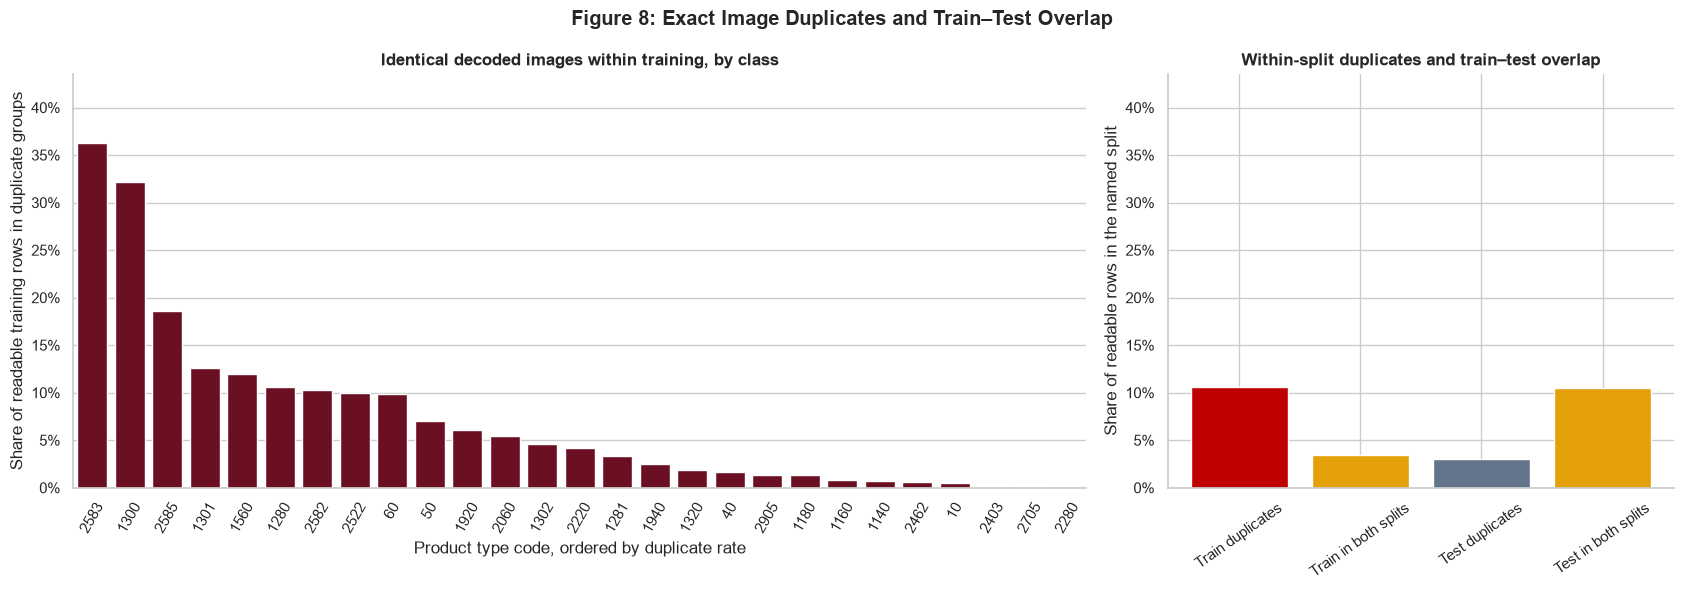

In [15]:
image_duplicate_by_class = (
    readable_images.loc[readable_images["split"].eq("train")]
    .groupby("prdtypecode", as_index=False)
    .agg(
        readable_products=("pixel_sha256", "size"),
        duplicate_rate=("is_duplicate_within_split", "mean"),
        conflicting_rows=("has_training_label_conflict", "sum"),
    )
    .sort_values(["duplicate_rate", "prdtypecode"], ascending=[False, True])
)

if not readable_images.empty:
    fig, axes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [2, 1]})
    if not image_duplicate_by_class.empty:
        sns.barplot(
            data=image_duplicate_by_class,
            x="prdtypecode", y="duplicate_rate",
            order=image_duplicate_by_class["prdtypecode"],
            color=PALETTE["secondary"], ax=axes[0],
        )
    axes[0].set_title("Identical decoded images within training, by class")
    axes[0].set_xlabel("Product type code, ordered by duplicate rate")
    axes[0].set_ylabel("Share of readable training rows in duplicate groups")
    axes[0].tick_params(axis="x", labelrotation=60)

    rates = []
    for split in image_duplicate_summary.index:
        subset = readable_images.loc[readable_images["split"].eq(split)]
        if subset.empty:
            continue
        rates.append((f"{split.title()} duplicates", subset["is_duplicate_within_split"].mean()))
        if "test" in image_duplicate_summary.index:
            rates.append((f"{split.title()} in both splits", subset["in_both_splits"].mean()))
    axes[1].bar(
        [label for label, _ in rates], [rate for _, rate in rates],
        color=[PALETTE["primary"], PALETTE["accent"], PALETTE["neutral"], PALETTE["accent"]][:len(rates)],
    )
    axes[1].set_title("Within-split duplicates and train–test overlap")
    axes[1].set_ylabel("Share of readable rows in the named split")
    axes[1].tick_params(axis="x", labelrotation=35)
    for axis in axes:
        axis.yaxis.set_major_formatter(lambda value, _: f"{value:.0%}")
        axis.set_ylim(0, min(1.05, max(0.05, max([rate for _, rate in rates] + image_duplicate_by_class["duplicate_rate"].tolist()) * 1.2)))
    fig.suptitle("Figure 8: Exact Image Duplicates and Train–Test Overlap", fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("No readable images: duplicate rates cannot be plotted.")


### How to read the duplicate counts

For a hash group containing three catalog rows, **duplicate rows = 3**, **duplicate groups = 1**, and **redundant rows = 2**. Duplicate rates count **all members** of a repeated group and use readable rows in the relevant split as their denominator.

A group shared by train and test may contain only one training row and one test row: that is **overlap**, but not a within-training or within-test duplicate. The summary reports these measures separately.

An identical image assigned to different training classes is a **label-conflict candidate**, not automatically a labeling error. Generic cover images, placeholders or shared packaging can legitimately represent different products. The example gallery is intended for review.

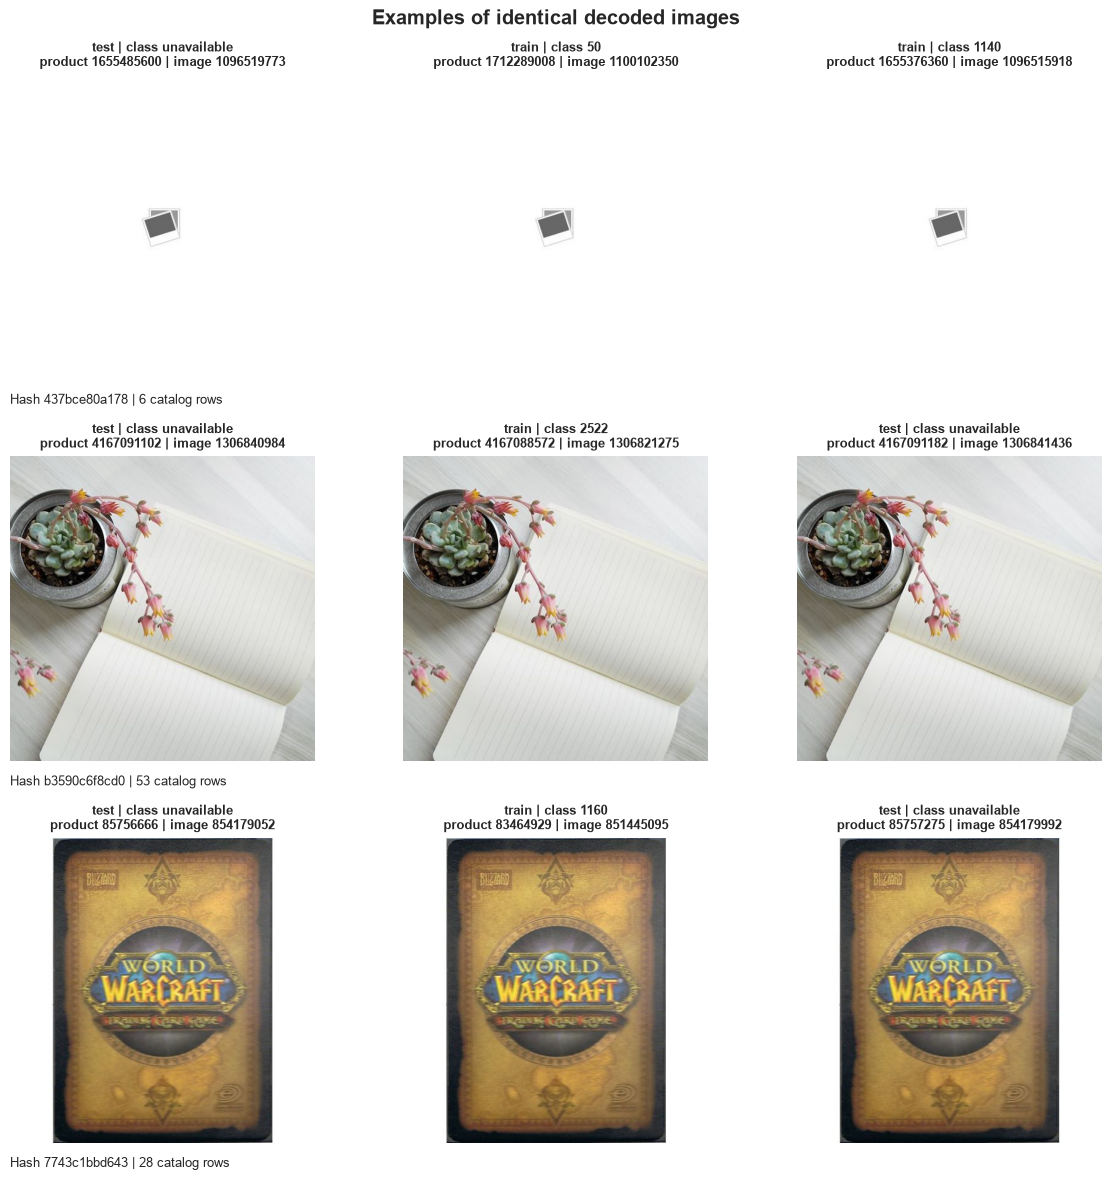

In [16]:
# Deterministic examples: a label conflict, a shared group, and a large group.
example_hashes = []
candidate_groups = [
    duplicate_image_groups.loc[duplicate_image_groups.index.isin(conflicting_image_groups.index)],
    duplicate_image_groups.loc[duplicate_image_groups.index.isin(shared_image_hashes)],
    duplicate_image_groups,
]
for candidates in candidate_groups:
    for pixel_hash in candidates.index:
        if pixel_hash not in example_hashes:
            example_hashes.append(pixel_hash)
            break

if example_hashes:
    fig, axes = plt.subplots(len(example_hashes), 3, figsize=(12, 4 * len(example_hashes)), squeeze=False)
    for row_index, pixel_hash in enumerate(example_hashes):
        members = duplicate_image_members.loc[duplicate_image_members["pixel_sha256"].eq(pixel_hash)]
        # Show different labels/splits first, so conflicts and overlap are visible.
        ordered = members.sort_values(["split", "prdtypecode", "productid"], na_position="last")
        representatives = pd.concat([
            ordered.drop_duplicates(["split", "prdtypecode"]), ordered,
        ]).drop_duplicates(["split", "source_row"]).head(3)
        for axis in axes[row_index]:
            axis.axis("off")
        for column_index, (_, member) in enumerate(representatives.iterrows()):
            axis = axes[row_index, column_index]
            with load_image(int(member["imageid"]), int(member["productid"]), split=f"image_{member['split']}") as image:
                axis.imshow(ImageOps.exif_transpose(image).convert("RGB"))
            label = str(int(member["prdtypecode"])) if pd.notna(member["prdtypecode"]) else "unavailable"
            axis.set_title(
                f"{member['split']} | class {label}\n"
                f"product {int(member['productid'])} | image {int(member['imageid'])}",
                fontsize=9,
            )
        axes[row_index, 0].text(
            0, -0.08, f"Hash {pixel_hash[:12]} | {len(members):,} catalog rows",
            transform=axes[row_index, 0].transAxes, fontsize=9,
        )
    fig.suptitle("Examples of identical decoded images", fontweight="bold")
    plt.tight_layout()
    plt.show()
else:
    print("No exact pixel-image duplicates were found.")


In [17]:
training_summary = image_duplicate_summary.loc["train"]
training_readable = int(training_summary["readable_rows"])
training_duplicate_rows = int(training_summary["pixel_duplicate_rows"])
training_duplicate_rate = training_duplicate_rows / training_readable if training_readable else 0.0

insight(
    "Finding 8 — repeated images need a separate leakage and label audit",
    (
        f"{training_duplicate_rows:,} of {training_readable:,} readable training rows "
        f"({training_duplicate_rate:.1%}) belong to a repeated decoded-image group. "
        f"These groups contain {int(training_summary['redundant_pixel_rows']):,} additional rows "
        f"beyond one representative per group."
    ),
    (
        f"{int(training_summary['pixel_duplicate_groups']):,} training pixel-duplicate groups; "
        f"{len(conflicting_image_groups):,} groups with conflicting training labels "
        f"({int(conflicting_image_groups['rows'].sum()):,} rows); "
        f"{len(shared_image_hashes):,} image groups shared by train and test; "
        f"{len(image_failures):,} unreadable or missing images across the audited catalog. "
        "All counts use the full referenced image catalog, not a sample."
    ),
    (
        "Keep identical-image groups in the same validation fold. If title and image "
        "duplicates are both used for grouping, connect overlapping groups so neither "
        "type can cross folds. Review conflicting labels and generic placeholder images "
        "before deciding whether to remove or downweight rows. Treat official train–test "
        "overlap as an audit finding; it does not by itself prove incorrect labels or "
        "justify modifying the official test set."
    ),
)


### Finding 8 — repeated images need a separate leakage and label audit

**Observation.** 8,956 of 84,916 readable training rows (10.5%) belong to a repeated decoded-image group. These groups contain 5,692 additional rows beyond one representative per group.

**Quantitative validation.** 3,264 training pixel-duplicate groups; 479 groups with conflicting training labels (1,074 rows); 1,265 image groups shared by train and test; 0 unreadable or missing images across the audited catalog. All counts use the full referenced image catalog, not a sample.

**Business implication.** Keep identical-image groups in the same validation fold. If title and image duplicates are both used for grouping, connect overlapping groups so neither type can cross folds. Review conflicting labels and generic placeholder images before deciding whether to remove or downweight rows. Treat official train–test overlap as an audit finding; it does not by itself prove incorrect labels or justify modifying the official test set.

## 11. Preprocessing Decisions Supported by Figures 3+

- Keep `has_description` as an explicit feature if validation confirms that it helps.
- Compare designation-only, description-only and combined-text models.
- Use word and character representations for text.
- Keep repeated normalized designations and identical decoded images within one validation fold; connect overlapping title/image groups when using both criteria.
- Review duplicate-image groups with conflicting training labels and generic placeholder images before removing or downweighting rows.
- Report train–test image overlap separately from duplicates within each split; leave the official test data unchanged.
- Keep image paths and loading centralized through `src.data_utils`.
- Figure 8 audits the complete training image catalog and includes test images when the project's test CSV is available. Its hash cache is stored under `data/processed/`.